# UV-Vis Analysis: Band Gap Determination

This notebook analyzes UV-Vis spectroscopy data to determine the optical band gap and absorption coefficient of thin film semiconductor materials. The analysis is divided into three main sections:

1. **Absorption Coefficient Calculation** - Converts reflectance and transmittance data to absorption coefficient
2. **Combined Tauc Plot Overview** - Generates comparison plots of all samples
3. **Individual Tauc Plots & Band Gap Extraction** - Calculates optical band gaps using the Tauc method
4. **Absorption File extraction for SCAPS-1D** - Converts the data to a readable file for SCAPS

## Methodology: Accurate Determination of Absorption Coefficient and Reflectance

Based on the work of [David. C Look](https://doi.org/10.1116/1.4954211).

### Theory of Light Interaction with Thin Films

When light passes through a thin film sample, it experiences reflections at both the air-film and film-substrate interfaces, as well as absorption within the material. The optical behavior is described by the transmittance and reflectance at both interfaces.

#### Transmittance Equation

The measured transmittance accounting for reflections at both the top and bottom surfaces is:

$$T_{\text{meas}} = \frac{(1-R)^2 e^{-\alpha d}}{1 - R^2 e^{-2\alpha d}} \quad \text{(1)}$$

Where:
- **$T_{\text{meas}}$** is the measured transmittance
- **R** is the "reflection coefficient"
- **α** is the absorption coefficient (cm⁻¹)
- **d** is the thickness of the film (cm)

This equation contains two unknowns: α and R. Therefore, a second independent equation is needed to solve for both parameters simultaneously.

#### Reflectance Equation

The measured reflectance is given by:

$$R_{\text{meas}} = R + \frac{R(1-R)^2 e^{-2\alpha d}}{1 - R^2 e^{-2\alpha d}} \quad \text{(2)}$$

This second equation allows us to determine both R and α from the measured values of $T_{\text{meas}}$ and $R_{\text{meas}}$ at each wavelength.

#### Absorbance

For completeness, the absorbance is defined as:

$$A_{\text{meas}} = \frac{(1-R)(1 - e^{-\alpha d})}{1 - R e^{-\alpha d}} \quad \text{(3)}$$

Note that by definition: $T_{\text{meas}} + R_{\text{meas}} + A_{\text{meas}} = 1$

#### Regime of Validity

From Eq. (2), it is immediately clear that:
- **If αd >> 1** (high absorption regime): $R_{\text{meas}} \approx R$, which means the simple approximation $\alpha = -\frac{1}{d}\ln\left[\frac{T_{\text{meas}}}{(1-R_{\text{meas}})^2}\right]$ becomes accurate without needing to solve the full system.

- **If αd ≤ 1** (low absorption regime): By solving equations (1) and by using a algebric manipulation of the equations (2) and (3) **simultaneously** we determine both α and R accurately. This is the case for most semiconductors near their absorption edge, where we need precise band gap determination.

### Implementation: Solving the System of Equations

For low absorption regions (where $\alpha d < 1$), we solve the coupled system:

$$\begin{cases}
T_{\text{meas}} = \frac{(1-R)^2 e^{-\alpha d}}{1 - R^2 e^{-2\alpha d}} \\
e^{-2\alpha d} = \frac{R_{\text{meas}} - R}{R(1 - 2R + R R_{\text{meas}} )}
\end{cases}$$

Using numerical methods (the `fsolve` function in our code), we determine the corrected values of both α and R from the measured $T_{\text{meas}}$ and $R_{\text{meas}}$ data. This ensures that the absorption coefficient reflects the true optical properties of the material.

### Photon Energy Calculation

The photon energy in eV is calculated from the wavelength using:

$$h\nu = \frac{hc}{\lambda} \cdot \frac{1}{e} \quad \text{(4)}$$

Where:
- **h** is Planck's constant (6.626 × 10⁻³⁴ J·s)
- **c** is the speed of light (3 × 10⁸ m/s)
- **λ** is the wavelength (nm)
- **e** is the elemental charge (1.602 × 10⁻¹⁹ C)

## Tauc Plot Method for Band Gap Determination

Following the Tauc method, the optical band gap is determined by analyzing the absorptive behavior near the absorption edge. The fundamental relationship is:

$$(h\nu \cdot \alpha)^{1/\gamma} = B(h\nu - E_g) \quad \text{(5)}$$

Where:
- **γ** denotes the type of electronic transition:
  - **γ = 1/2** for direct allowed transitions (direct band gap)
  - **γ = 2** for indirect allowed transitions (indirect band gap)
- **B** is a material-dependent proportionality constant
- **$E_g$** is the optical band gap energy (eV)

#### Band Gap Extraction Procedure

The band gap is determined by:

1. **Data Filtering**: Select the energy range near the absorption edge where linear behavior is observed
2. **Linear Extrapolation**: Identify and extrapolate the linear region of the Tauc plot
3. **X-axis Intercept**: Find where the extrapolated line crosses the x-axis (where $(h\nu \cdot \alpha)^{1/\gamma} = 0$)
4. **Band Gap Value**: This x-intercept gives $E_g$

#### Practical Implementation

- **Direct band gap (allowed transitions)**: Plot $(αhν)^2$ vs $hν$ (using $\gamma = 1/2$)
- **Indirect band gap (forbidden transitions)**: Plot $(αhν)^{1/2}$ vs $hν$ (using $\gamma = 2$)

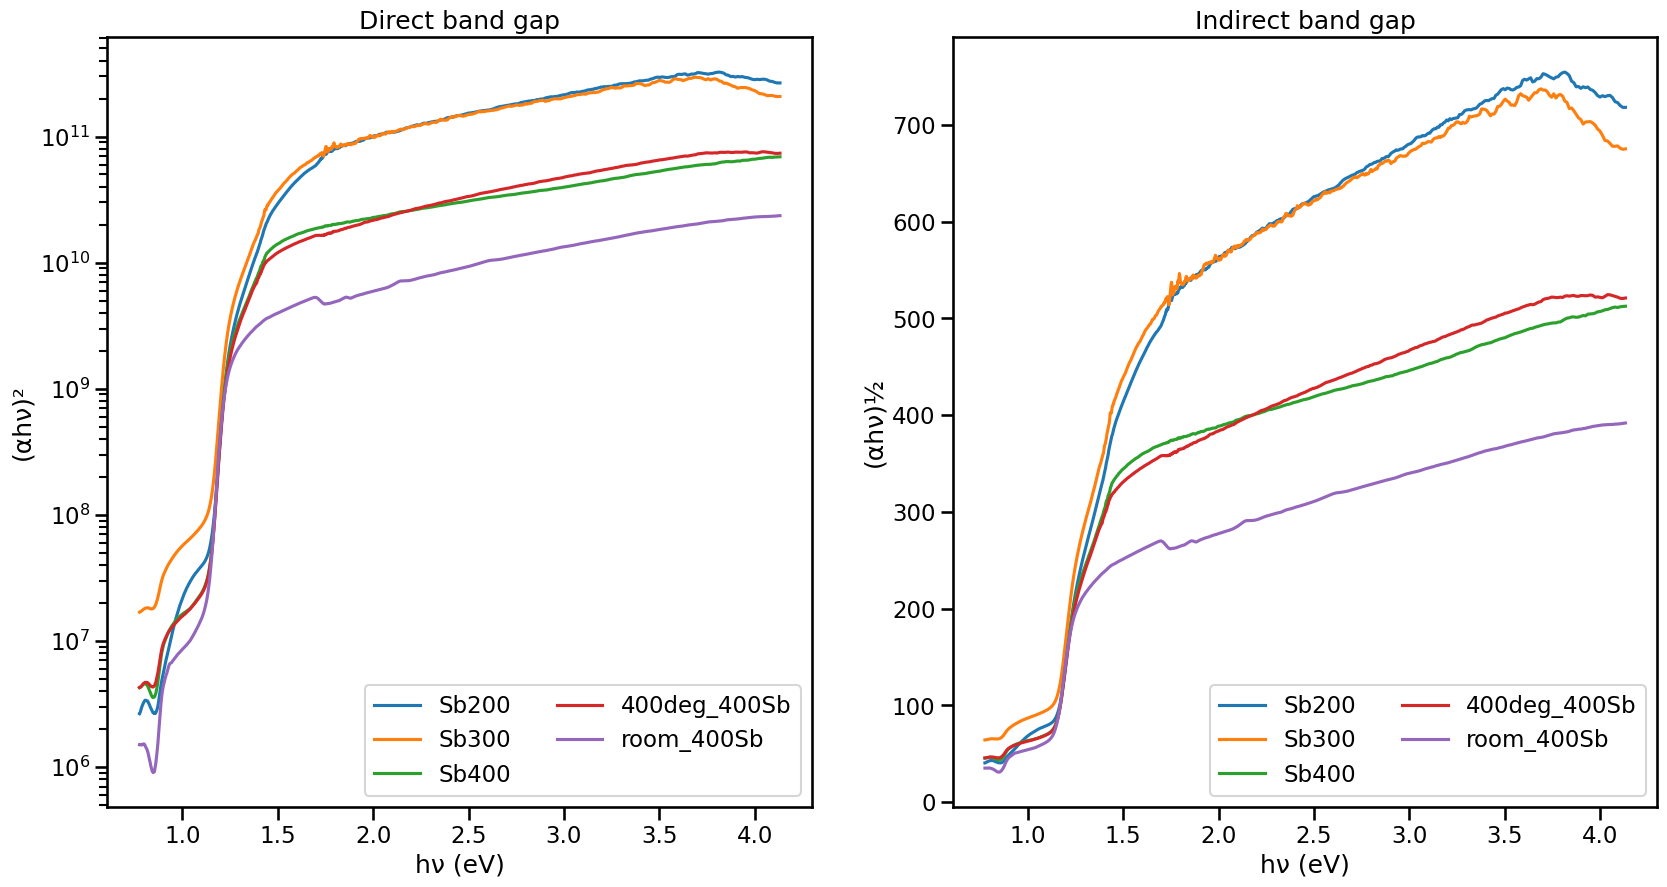

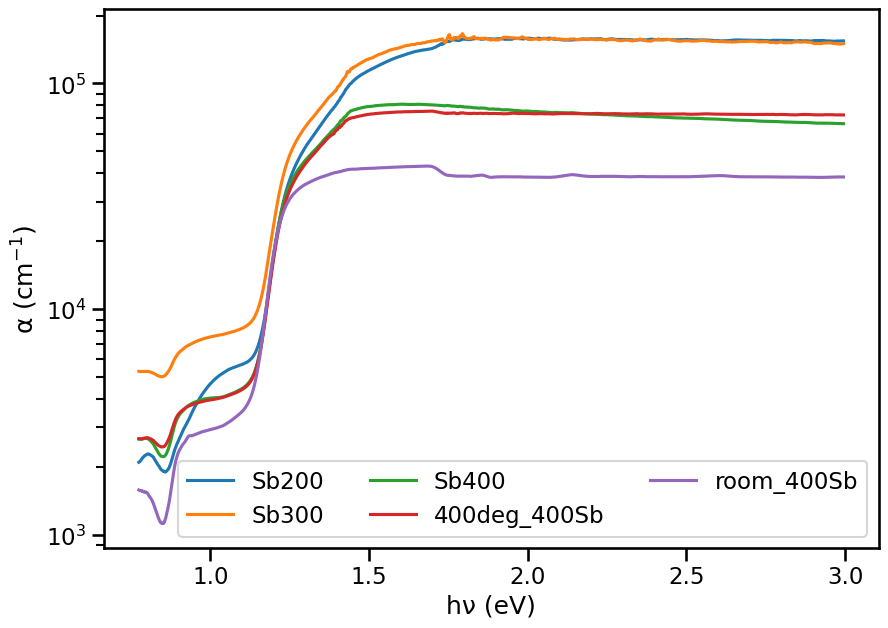

In [6]:
import sys
from pathlib import Path
current_path = Path.cwd().resolve()
for parent in [current_path] + list(current_path.parents):
    if (parent / 'project_paths.py').exists():
        sys.path.insert(0, str(parent))
        break

from project_paths import data_path

#Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import glob as gl
import seaborn as sns
import os
from scipy.optimize import fsolve
import warnings

# Ignorar os avisos matemáticos normais do solver
warnings.filterwarnings('ignore')

# File path to the Excel file
FILE_PATH = data_path('UV-Vis', '2nd Round', 'Sb_2_3_4__2.xlsx')

# Set output directory for plots
PLOTS_DIR = "Plots"
os.makedirs(PLOTS_DIR, exist_ok=True)

# Physical constants
h = 6.62607015e-34  # Planck's constant (J·s)
c = 299792458       # Speed of light (m/s)
e = 1.602176634e-19 # Elementary charge (C)

# Load all sheets from Excel
xls = pd.ExcelFile(FILE_PATH)
sheet_names = xls.sheet_names

# Dictionary to store processed data
res = {}

sns.set_context('talk')

#Create the Tauc plots for all the samples
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,10))
fig1, ax3 = plt.subplots(1, 1, figsize=(10, 7))

for sheet_name in sheet_names:
        # Read the sheet
        df = pd.read_excel(FILE_PATH, sheet_name=sheet_name)
        
        # Get wavelength and optical properties
        wavelength = df['wavelength'].values
        
        # Determine which columns contain T and R
        if 'T' in df.columns:
            transmittance = df['T'].values / 100  # Convert percentage to fraction
        else:
            transmittance = df.iloc[:, 1].values / 100  
            
        transmittance[transmittance <= 0] = 1E-10 # Array-safe assignment
            
        if 'R' in df.columns:
            reflectance = df['R'].values / 100  # Convert percentage to fraction
        else:
            reflectance = df.iloc[:, 2].values / 100  
            
        reflectance[reflectance <= 0] = 1E-10 # Array-safe assignment

        # Filter out data points where R + T >= 1
        reflectance_ = reflectance[reflectance + transmittance < 1]
        transmittance_ = transmittance[reflectance + transmittance < 1]
        wavelength_ = wavelength[reflectance + transmittance < 1]

        
        # Get thickness (in nm)
        if 'thickness' in df.columns:
            thickness_nm = df['thickness'].dropna().iloc[0]
        
        t_cm = thickness_nm * 1e-7 
        
        # 2. Calculate the inicial alpha
        alpha_i = (1 / t_cm) * np.log(((1 - reflectance_)**2) / transmittance_)
        
        alpha_final_array = np.zeros_like(alpha_i)
        R_final_array = np.copy(reflectance_) 
        
        for i in range(len(wavelength_)):
            T_val = transmittance_[i]
            R_val = reflectance_[i]
            a_i_val = alpha_i[i]
            
            if a_i_val * t_cm < 1:
                
                def sistema_equacoes(variables):
                    a_var, R_var = variables
                    
                    # Proteção contra Overflow: limita o limite inferior do expoente
                    # Evita que o fsolve entre em colapso com expoentes absurdos
                    val_at = max(-a_var * t_cm, -700)
                    val_2at = max(-2 * a_var * t_cm, -700)
                    
                    exp_at = np.exp(val_at)
                    exp_2at = np.exp(val_2at)
                    
                    denominador = 1 - (R_var**2) * exp_2at
                    if denominador == 0:
                        denominador = 1e-10
                    
                    eq1 = ((((1 - R_var)**2) * exp_at) / denominador) - T_val
                    eq2 = ((R_val - R_var) / (R_var * (1 - (2 * R_var + R_var * R_val)))) - exp_2at
                    return [eq1, eq2]
                
                inicial_estimate = [a_i_val, R_val] 
                
                # CORREÇÃO: Usar full_output=True para saber se a convergência falhou
                solucao, infodict, ier, mesg = fsolve(sistema_equacoes, inicial_estimate, full_output=True)
                
                # ier == 1 indica que a raiz/solução convergiu com sucesso
                if ier == 1:
                    alpha_final_array[i] = solucao[0]
                    R_final_array[i] = solucao[1] # Passa a usar também o R do sistema
                else:
                    alpha_final_array[i] = a_i_val 
                    
            else:
                # Condição satisfeita (alpha*t >= 1), usa a aproximação inicial
                alpha_final_array[i] = a_i_val
        
        x = (h * c) / (wavelength_ * 10**-9) / e
        
        y = alpha_i
        y_DA = (y * x)**2
        y_IA = (y * x)**(0.5)

        # Store in dictionary (Agora com o R_calculado do fsolve também incluído)
        res[sheet_name] = {
            'hv': x,
            'alpha': y,
            'DA': np.nan_to_num(y_DA),
            'IA': np.nan_to_num(y_IA),
            'nm': wavelength_,
            'R_medido': reflectance_,
            'R_calculado': R_final_array,
            'T': transmittance_
        }
        
        # Plot the data
        ax1.plot(x, y_DA, label=sheet_name)
        ax2.plot(x, y_IA, label=sheet_name)

        # Absorbance plot
        small_range_mask = x < 3
        small_range_x = x[small_range_mask]
        small_range_y = y[small_range_mask]
        ax3.plot(small_range_x, small_range_y, label=sheet_name)

# Fix the graph of direct band gap
ax1.legend(ncols=2)
ax1.set_ylabel(r'(αhν)²')
ax1.set_xlabel(r'hν (eV)')
ax1.set_title('Direct band gap')
ax1.set_yscale("log")

# Fix the graph of indirect band gap
ax2.legend(ncols=2)
ax2.set_ylabel(r'(αhν)½')
ax2.set_xlabel(r'hν (eV)')
ax2.set_title('Indirect band gap')

# Fix the graph of indirect band gap
ax3.legend(ncols=3)
ax3.set_ylabel(r'α (cm$^{-1}$)')
ax3.set_xlabel(r'hν (eV)')
ax3.set_yscale("log")
#ax3.set_xlim([0,3])

# Save the values of the tauc plot in excel files
with pd.ExcelWriter(os.path.join(PLOTS_DIR, "results_tauc_plot.xlsx")) as writer:
  for label_plot, data in res.items():
      df_export = pd.DataFrame(data)
      df_export.to_excel(writer, index=False, sheet_name=label_plot )

# Save the combined plots
fig.savefig(os.path.join(PLOTS_DIR, 'Combined_Direct_Indirect_BandGap.png'), dpi=300, bbox_inches='tight')
fig1.savefig(os.path.join(PLOTS_DIR, 'Absorption_Coefficient.png'), dpi=300, bbox_inches='tight')

plt.show()


## Band Gap Extraction
### Procedure

1. **Data Smoothing**: Apply Savitzky-Golay filter to reduce noise
2. **Linear Region Identification**: Find the region with maximum slope (derivative) in the Tauc plot
3. **Extrapolation**: Fit a line through the linear region
4. **Band Gap Extraction**: The x-intercept (where y=0) gives the optical band gap $E_g$



Calculating Bandgaps...


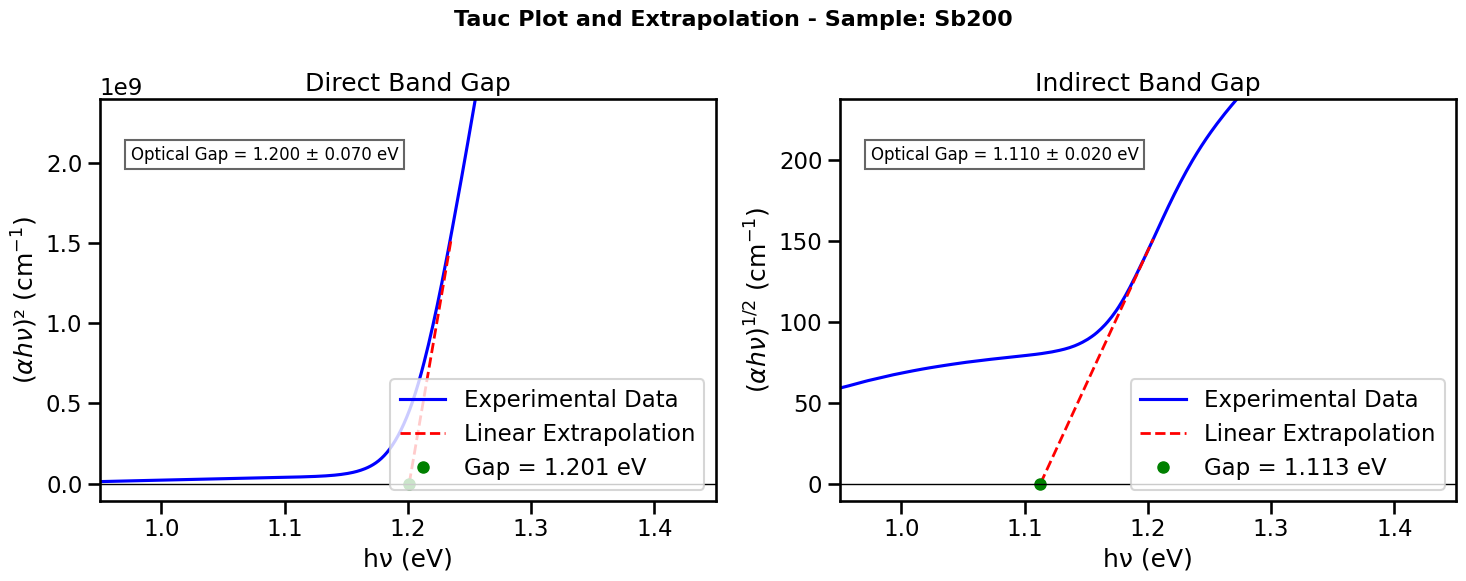

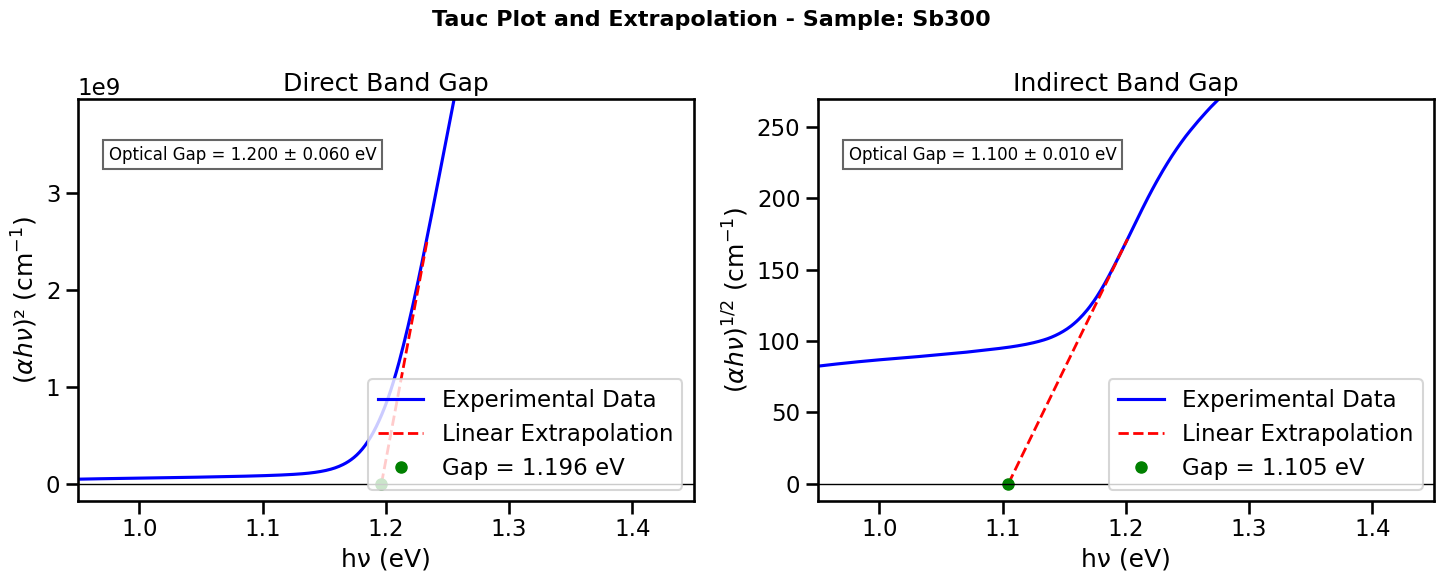

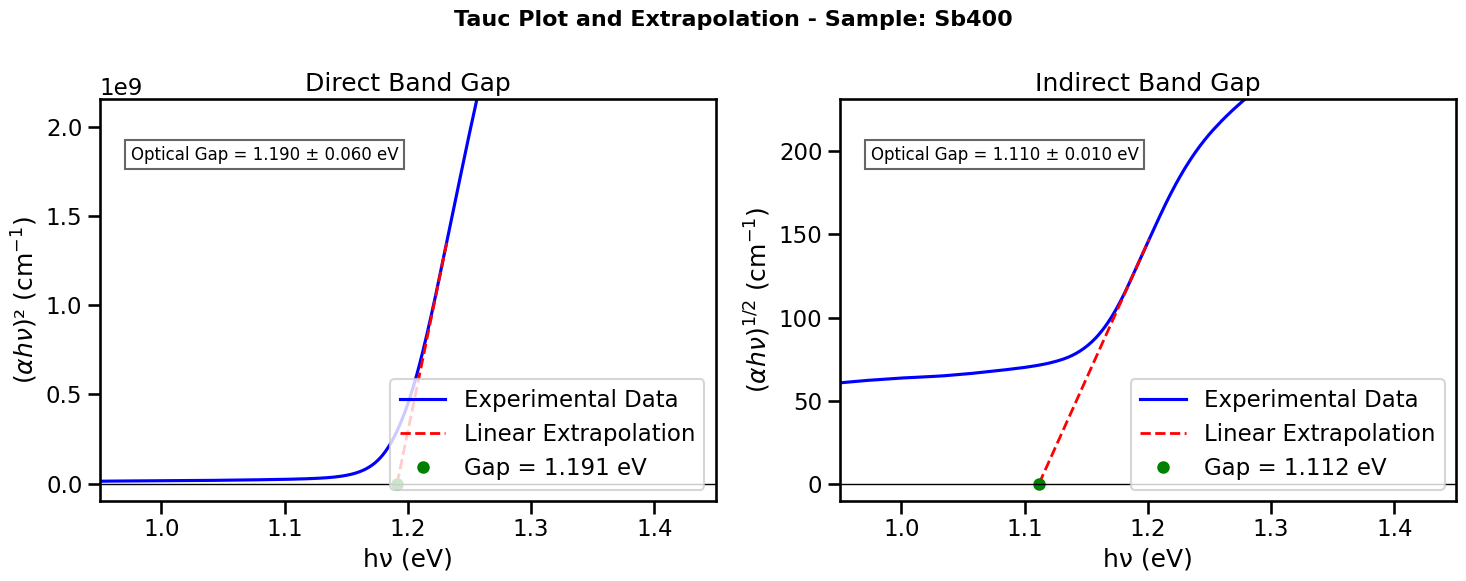

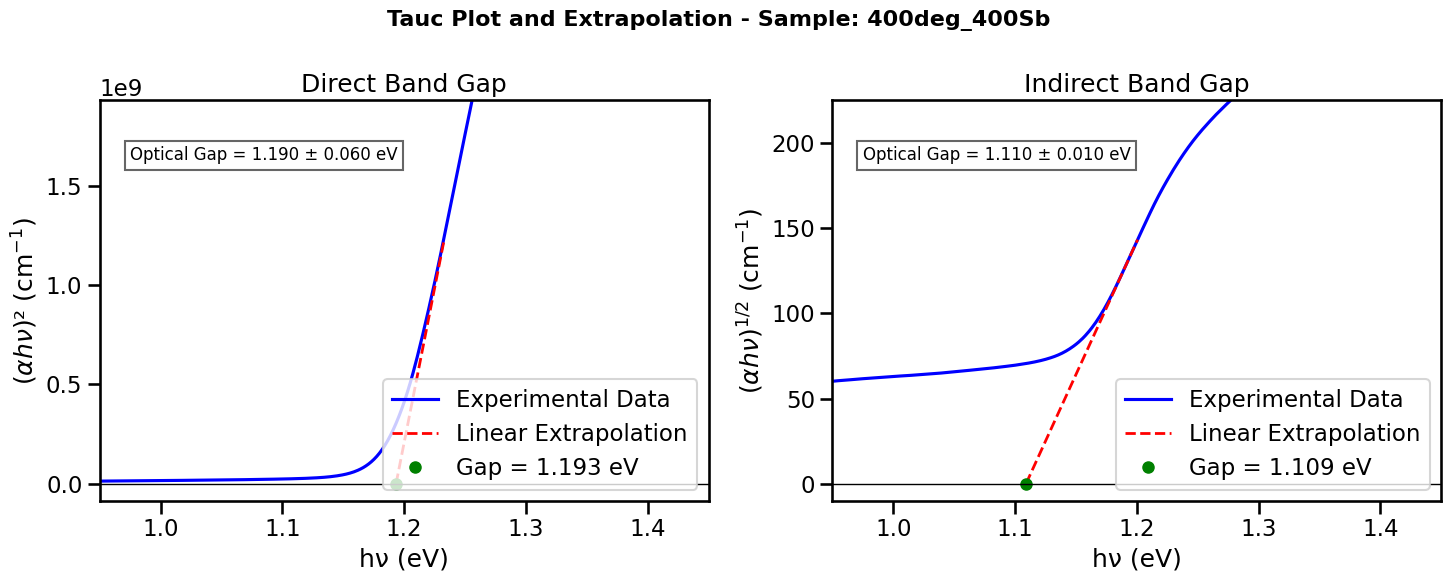

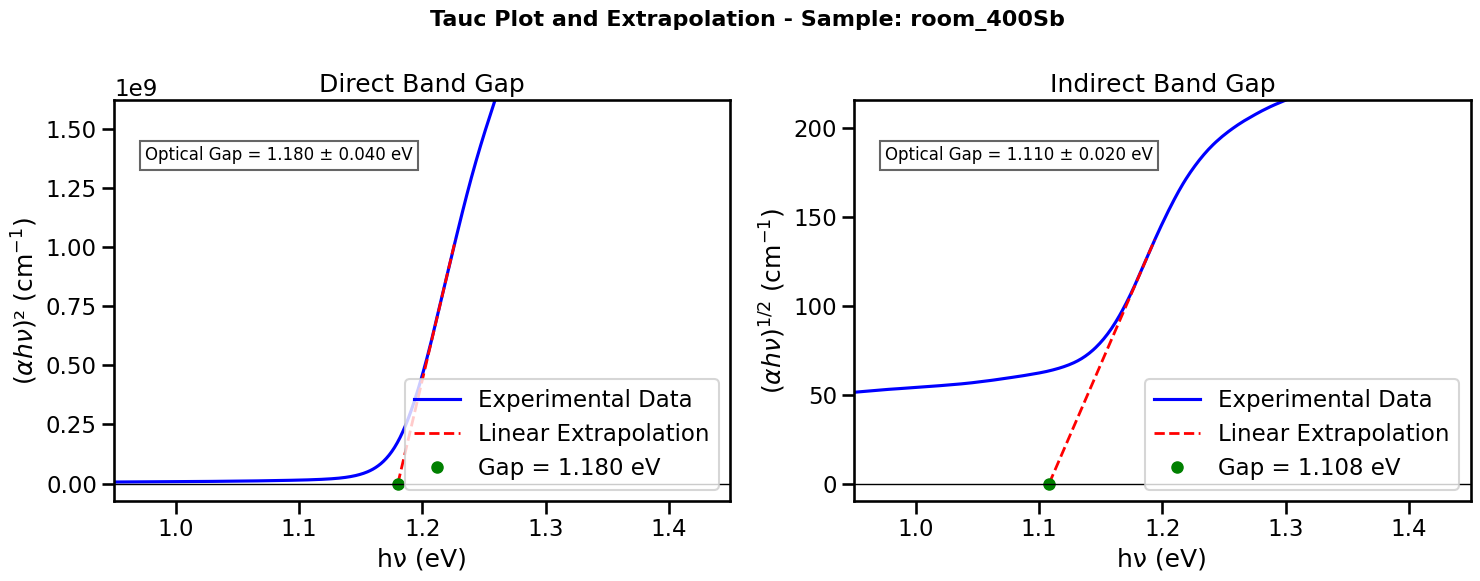


--- Summary of Calculated Bandgaps ---
      Sample     Type  Gap (eV)  Error (eV)
       Sb200   Direct  1.201085    0.065611
       Sb200 Indirect  1.112809    0.016594
       Sb300   Direct  1.196451    0.059823
       Sb300 Indirect  1.104672    0.014801
       Sb400   Direct  1.191278    0.056649
       Sb400 Indirect  1.111696    0.012507
400deg_400Sb   Direct  1.193324    0.055582
400deg_400Sb Indirect  1.108950    0.011737
  room_400Sb   Direct  1.180118    0.040274
  room_400Sb Indirect  1.108052    0.017564
Summary saved in folder: Plots


In [7]:
from scipy.signal import savgol_filter
import os

# Define the num_of_zeros function for decimal place formatting
def num_of_zeros(n):
  s = '{:.16f}'.format(n).split('.')
  if s[0] == '0':
    # For numbers < 1, count the leading zeros and add 1
    return len(s[1]) - len(s[1].lstrip('0')) + 1
  else:
    # For numbers >= 1, no leading zeros needed
    return 0

print("\nCalculating Bandgaps...")
gaps = []

# You can adjust these limits (in eV) to focus the analysis on the rising edge of the material
# and ignore noise at low energies or substrate (Glass) absorption at high energies.
min_energy = 1.15
max_energy = 1.25

for k in res.keys():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,6))
    fig.suptitle(f'Tauc Plot and Extrapolation - Sample: {k}', fontsize=16, fontweight='bold')

    x_hv = res[k]['hv']
    
    # Extrapolation for both Direct (ax1) and Indirect (ax2) Bandgaps
    plots_info = [
        {'ax': ax1, 'y_data': res[k]['DA'], 'title': 'Direct Band Gap', 'ylabel': r'$(αhν)²$ (cm$^{-1}$)'},
        {'ax': ax2, 'y_data': res[k]['IA'], 'title': 'Indirect Band Gap', 'ylabel': r'$(αhν)^{1/2}$ (cm$^{-1}$)'}
    ]

    for info in plots_info:
        ax = info['ax']
        y_data = info['y_data']

        # 1. Filter the data only for the region of interest (avoid noise at the edges)
        mask = (x_hv >= min_energy) & (x_hv <= max_energy)
        x_fit = x_hv[mask]
        y_fit = y_data[mask]

        if len(x_fit) < 10:
            ax.text(0.5, 0.5, 'Insufficient data in the region', transform=ax.transAxes)
            continue

        # 2. Smooth the data to obtain a clean derivative (Savitzky-Golay Filter)
        # The window size must be odd
        window_len = min(25, len(y_fit) - (1 if len(y_fit) % 2 == 0 else 0))
        if window_len > 2:
            y_smooth = savgol_filter(y_fit, window_length=window_len, polyorder=2)
        else:
            y_smooth = y_fit

        # 3. Calculate the First Derivative (Gradient)
        d1 = np.gradient(y_smooth, x_fit)

        # 4. Find the point of maximum slope (linear region of the Tauc Plot)
        max_idx = np.argmax(d1)
        x_0 = x_fit[max_idx]
        y_0 = y_smooth[max_idx]
        m = d1[max_idx] # The slope (m)

        # 5. Extrapolation line equation: y = m*x + c  =>  c = y_0 - m*x_0
        c = y_0 - m * x_0

        # 6. Calculate the Optical Bandgap (X-axis intersection, where y = 0)
        # 0 = m*x + c => x = -c/m
        x_cross = -c / m
        
        # 7. Error estimation using linear regression on the smoothed data
        # Fit a linear function to the data around the maximum slope region
        # to get reliable slope and intercept uncertainties
        coeffs, cov = np.polyfit(x_fit, y_smooth, 1, cov=True)
        m_fit = coeffs[0]
        c_fit = coeffs[1]
        
        # Extract uncertainties from covariance matrix
        sigma_m = np.sqrt(cov[0, 0])  # Uncertainty in slope
        sigma_c = np.sqrt(cov[1, 1])  # Uncertainty in intercept
        
        # Error propagation for bandgap: x_cross = -c/m
        # Using partial derivatives: dx/dc = -1/m, dx/dm = c/m^2
        sigma_bg = np.sqrt((sigma_c / m_fit)**2 + (c_fit * sigma_m / (m_fit**2))**2)
        
        # Determine appropriate number of decimal places for displaying the uncertainty
        decimals = num_of_zeros(sigma_bg)
        
        # Save the values
        gap_type = 'Direct' if 'Direct' in info['title'] else 'Indirect'
        gaps.append({'Sample': k, 'Type': gap_type, 'Gap (eV)': x_cross, 'Error (eV)': sigma_bg})

        # 8. Draw the plots
        # Plot original data
        ax.plot(x_hv, y_data, 'b-', label='Experimental Data')
        
        # Plot extrapolation line (dashed red)
        y_max_plot = 0.7 * np.amax(y_fit) # Raise the line up to 70% of the maximum peak
        x_line_start = x_cross
        x_line_end = (y_max_plot - c) / m
        
        ax.plot([x_line_start, x_line_end], [0, y_max_plot], 'r--', linewidth=2, label='Linear Extrapolation')
        
        # Mark the exact point of the Bandgap
        ax.plot(x_cross, 0, 'go', markersize=8, label=f'Gap = {x_cross:.3f} eV')
        
        # Axis formatting
        ax.axhline(0, color='black', linewidth=1)
        ax.set_xlabel(r'hν (eV)')
        ax.set_ylabel(info['ylabel'])
        ax.set_title(info['title'])
        ax.text(0.05, 0.85, f'Optical Gap = {round(x_cross, decimals):.3f} ± {round(sigma_bg, decimals):.3f} eV', 
                transform=ax.transAxes, fontsize=12, bbox=dict(facecolor='white', alpha=0.6))
        
        # Adjust the visual "window" of the plot
        ax.set_xlim(min_energy - 0.2, max_energy + 0.2)
        ax.set_ylim(-0.05 * np.amax(y_fit), 1.1 * np.amax(y_fit))
        ax.legend(loc='lower right')

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f'Tauc_plot_extrapolation_{k}.png'), dpi=300)
    plt.show()

# Export a summary with all calculated Bandgaps
print("\n--- Summary of Calculated Bandgaps ---")
df_gaps = pd.DataFrame(gaps)
print(df_gaps.to_string(index=False))

# Optional: Save to an Excel file
df_gaps.to_excel(os.path.join(PLOTS_DIR, "Summary_Bandgaps.xlsx"), index=False)
print(f"Summary saved in folder: {PLOTS_DIR}")


## 1. Why do we need to smooth the data?
In the case of the Tauc Plot, our goal in automatically finding the bandgap is to identify the region where the curve rises most steeply and linearly (the linear absorption region). Mathematically, we find the maximum slope by calculating the first derivative (the gradient) of the data and looking for the point where this derivative is at its maximum (which is what the np.argmax(d1) function does).

The problem is that the data coming out of the spectrophotometer is never mathematically a perfect line. They always have tiny oscillations caused by electronic noise, dust, or the detection limits of the equipment.

The derivative measures the difference between two consecutive points. If there is a small "jump" caused by noise between two points that are very close to each other on the X-axis, the slope between them will appear almost vertical.

The result is that the derivative of a noisy signal becomes full of random "spikes".

If we don't smooth the data first, the code would pick up one of these random noise spikes and declare it as the point of maximum slope, completely missing the actual ramp of the material (CdS).

## 2. What is the [Savitzky-Golay](https://www.bing.com/ck/a?!&&p=3d75b514299838f9d857d340f6910c4cc865649feb3be675d409aa57dbe44156JmltdHM9MTc3NjAzODQwMA&ptn=3&ver=2&hsh=4&fclid=39247e5c-644c-6408-2947-6a0b652b6592&psq=savitzky-golay+smoothing&u=a1aHR0cHM6Ly9laWdlbnZlY3Rvci5jb20vd3AtY29udGVudC91cGxvYWRzLzIwMjAvMDEvU2F2aXR6a3lHb2xheS5wZGY) method?
Invented in 1964 by Abraham Savitzky and Marcel Golay, it is a highly digital filtering algorithm, especially in spectroscopy and analytical chemistry.

If we used a simple "moving average" to smooth the data, the curve would become smoother, but the corners and ramps would become "flattened out" (smeared) and we would lose the true slope of the curve. The Savitzky-Golay method does something much smarter:

Sliding Window: It looks at a small group of points at a time (the window_length parameter, which we set to 25 points).

Polynomial Fit: Within this window, instead of simply calculating the average, it tries to draw a mathematical curve (a polynomial, like a parabola or a 2nd-degree curve) that best fits those specific points using the least squares method.

Sliding: It replaces the central point with the value of that perfect curve and then slides the window one point forward, repeating the process for the entire graph.

The result: It manages to clean up high-frequency noise without distorting the real shape of the curve and, most importantly, it preserves the original slopes, which is absolutely crucial when our next step is to calculate a derivative to draw a tangent line.

## 3. How is the Band Gap Uncertainty Calculated?

The uncertainty in the band gap determination arises from the uncertainties in the linear fit parameters (slope and intercept) of the Tauc plot's linear extrapolation region.

**Linear Regression Analysis:**
The extrapolation line follows the equation:
$$y = m \cdot x + c$$

where $m$ is the slope and $c$ is the y-intercept. By performing a linear regression on the smoothed data using `np.polyfit()`, we obtain not only the best-fit parameters but also their covariance matrix, which provides the uncertainties:
- $\sigma_m$ = uncertainty in the slope
- $\sigma_c$ = uncertainty in the intercept

**Band Gap Calculation:**
The optical band gap is determined as the x-axis intercept (where $y = 0$):
$$E_g = -\frac{c}{m}$$

**Error Propagation:**
To find the uncertainty in the band gap, we apply the error propagation formula. For a function $f(m, c) = -c/m$, the partial derivatives are:

$$\frac{\partial E_g}{\partial c} = -\frac{1}{m} \quad \text{and} \quad \frac{\partial E_g}{\partial m} = \frac{c}{m^2}$$

Thus, the uncertainty in the band gap is:

$$\sigma_{E_g} = \sqrt{\left(\frac{\partial E_g}{\partial c} \sigma_c\right)^2 + \left(\frac{\partial E_g}{\partial m} \sigma_m\right)^2} = \sqrt{\left(\frac{\sigma_c}{m}\right)^2 + \left(\frac{c \cdot \sigma_m}{m^2}\right)^2}$$

This approach ensures that the reported band gap value includes a realistic estimate of the measurement uncertainty, reflecting both the quality of the linear fit and the noise present in the experimental data. The uncertainty is displayed on the Tauc plot as $E_g \pm \sigma_{E_g}$ (in eV).


## Sigmoid-Boltzmann Function

Another way of determining the Eg, acording to [Zanatta](https://www.nature.com/articles/s41598-019-47670-y#Equ9), by doing a Sigmoid-Boltzmann fitting based on the absorption coefficient previously calculated can be done by the following function:

$$\alpha(E) = \alpha_{max} + \frac{\alpha_{min} - \alpha_{max}}{1 + \exp\left(\frac{E - E_0^{Boltz}}{δE}\right)} \quad (4)$$

where $\alpha_{min}$ and $\alpha_{max}$ stands for the minimum and maximum absorption coefficient respectively; $E_0^{Bolts}$ is the energy coordinate at which the absorption coefficient is halfway between $\alpha_{min}$ and $\alpha_{max}$; and $δE$ is associated with the slope of the sigmoid curve. In this case, 4 parameters will be optimized based on the absorption coefficient previously calculated ($\alpha_{comp}$) and the energy ($hν$) values.

After this, the direct and indirect band gap can be calculated as follows:

$$E_g^{dir} = E_0^{Boltz} - 0.3δE \quad (5)$$

$$E_g^{indir} = E_0^{Boltz} - 4.3δE \quad (6)$$

with 0.3 and 4.3 working as empirical constants determined by Zanatta from the corresponding direct and indirect results experimentally.


## SCAPS absorption file

Creation of the absorption file (.abs) to use on SCAPS.

Creating SCAPS absorption files...
✓ Plot saved: Plots\SCAPS_Absorption\Sb200_SCAPS_absorption_plot.png


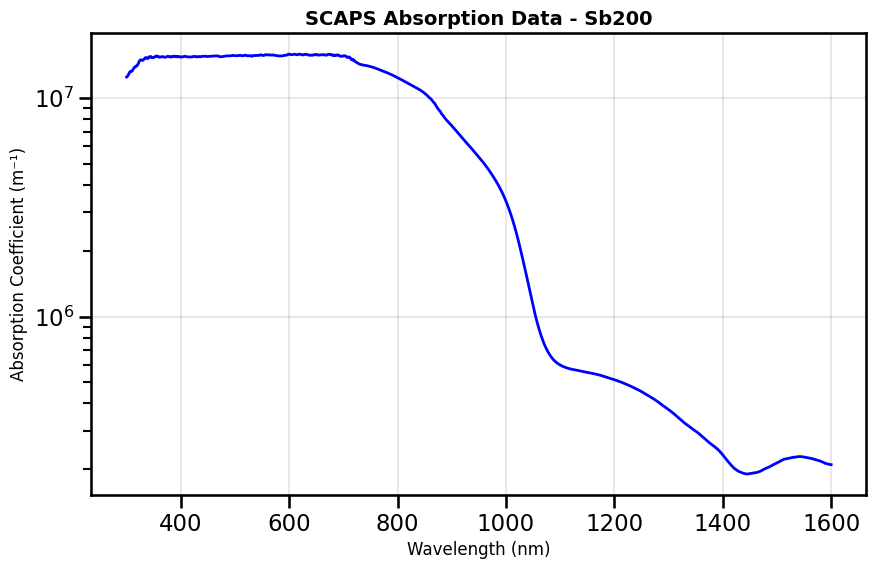

✓ Plot saved: Plots\SCAPS_Absorption\Sb300_SCAPS_absorption_plot.png


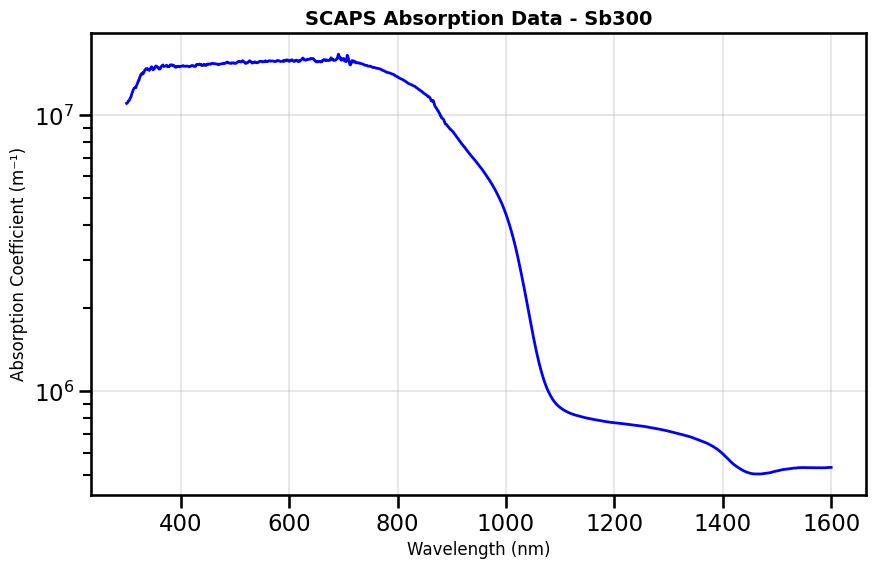

✓ Plot saved: Plots\SCAPS_Absorption\Sb400_SCAPS_absorption_plot.png


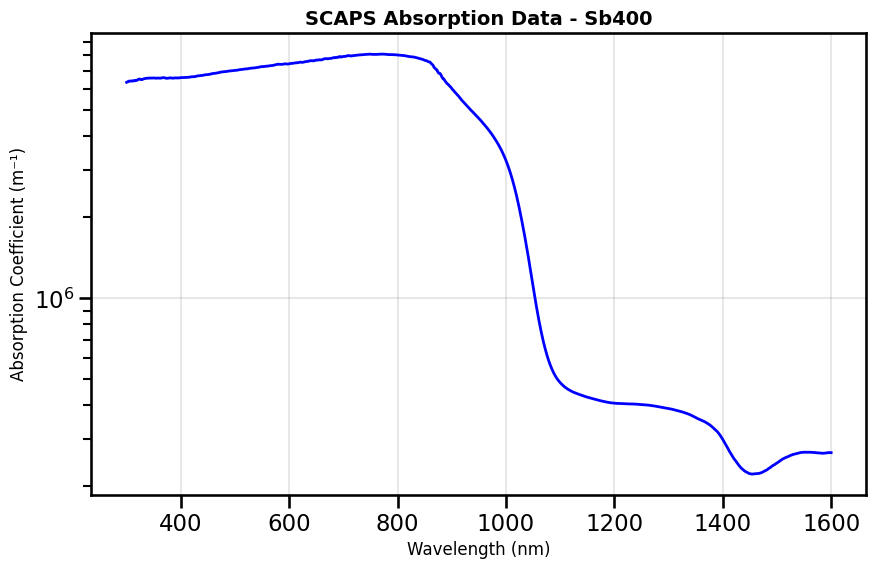

✓ Plot saved: Plots\SCAPS_Absorption\400deg_400Sb_SCAPS_absorption_plot.png


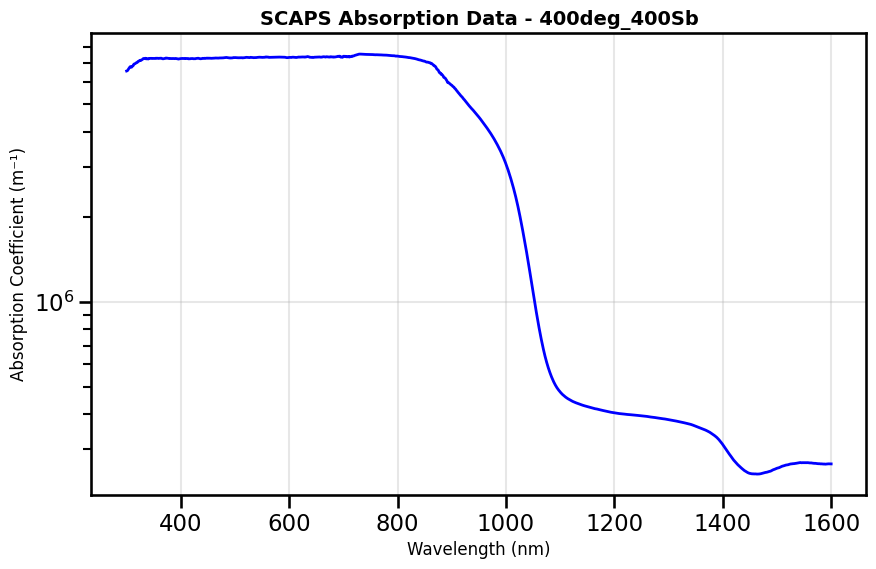

✓ Plot saved: Plots\SCAPS_Absorption\room_400Sb_SCAPS_absorption_plot.png


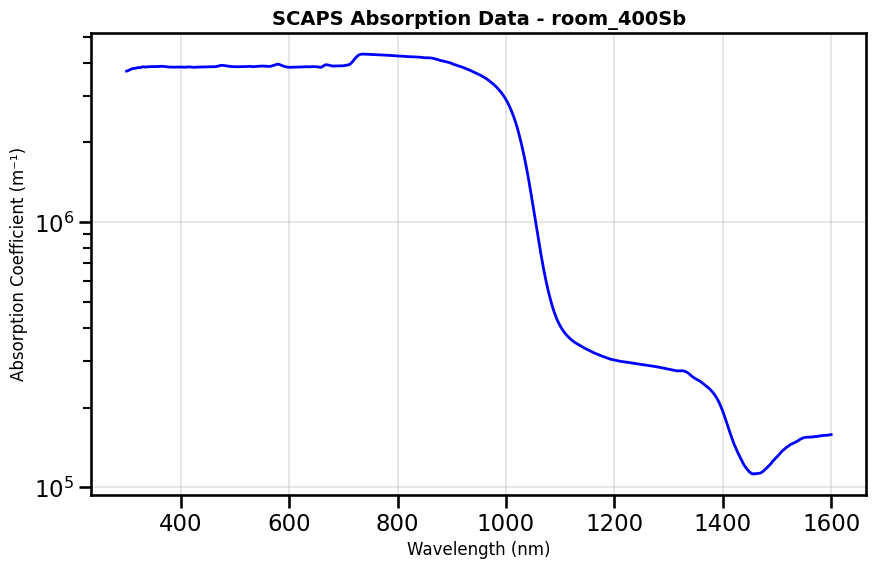


All SCAPS absorption files and plots saved in: Plots\SCAPS_Absorption


In [8]:
# Create SCAPS absorption files with wavelength and absorption coefficient
scaps_dir = os.path.join(PLOTS_DIR, "SCAPS_Absorption")
os.makedirs(scaps_dir, exist_ok=True)

print("Creating SCAPS absorption files...")

for sheet_name, data in res.items():
    # Extract wavelength (nm) and absorption coefficient (cm^-1)
    wavelength_nm = data['nm']
    absorption_coeff = data['alpha'] * 100  # Convert from cm^-1 to m^-1 for SCAPS
    
    # Create a dataframe with the two columns
    df_scaps = pd.DataFrame({
        'lambda[nm]': wavelength_nm,
        'alpha[m^-1]': absorption_coeff
    })
    
    
    
    # Generate plot for each sample
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Filter out non-finite values for plotting
    mask = np.isfinite(absorption_coeff)
    wavelength_clean = wavelength_nm[mask]
    absorption_clean = absorption_coeff[mask]

    # Filter positive absorption values only (SCAPS cannot handle negative or zero absorption)
    positive_mask = absorption_clean > 0
    wavelength_clean = wavelength_clean[positive_mask]
    absorption_clean = absorption_clean[positive_mask]

    # Create filename based on sheet name
    filename = os.path.join(scaps_dir, f"{sheet_name}_SCAPS_absorption.abs")
    
    # Save as text file with tabulated format, filtering out infinite values
    with open(filename, 'w') as f:
        f.write(f"/SCAPS Absorption Data - {sheet_name}\n")
        f.write("/lambda[nm]\talpha[m^-1]\n")
        
        for wl, alpha in zip(wavelength_clean, absorption_clean):
            # Only write if alpha is a finite number (not inf, -inf, or nan)
            if np.isfinite(alpha):
                f.write(f"{wl:.2f}\t{alpha:.6e}\n")
    
    ax.plot(wavelength_clean, absorption_clean, 'b-', linewidth=2)
    ax.set_xlabel('Wavelength (nm)', fontsize=12)
    ax.set_ylabel('Absorption Coefficient (m⁻¹)', fontsize=12)
    ax.set_title(f'SCAPS Absorption Data - {sheet_name}', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')
    
    # Save the plot
    plot_filename = os.path.join(scaps_dir, f"{sheet_name}_SCAPS_absorption_plot.png")
    fig.savefig(plot_filename, dpi=300, bbox_inches='tight')
    print(f"✓ Plot saved: {plot_filename}")
    
    plt.show()

print(f"\nAll SCAPS absorption files and plots saved in: {scaps_dir}")